# Social Media Engagement Analysis
Hackathon Project | Python Data Analytics

## Problem Statement
The dataset contains social media post information from multiple platforms, but inconsistent entries, missing values, duplicate records, and invalid numerical values can affect the reliability of analysis.

The challenge is to clean and standardize the dataset and analyze social media engagement patterns to identify useful platform and content performance insights.

## Objectives
- Clean and prepare the raw social media dataset.
- Standardize inconsistent platform and content-type names.
- Handle missing, duplicate, and invalid records.
- Analyze engagement patterns using statistical methods and visualizations.
- Identify platform and content performance insights.
- Provide data-driven recommendations for improving social media engagement.

## 1. Installing Python Libraries

In [2]:
!pip install numpy

In [3]:
!pip install pandas

In [4]:
!pip install matplotlib

In [5]:
!pip install seaborn

### Importing libraries

In [6]:
import numpy as np
import pandas as pd

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading Dataset

In [97]:
# .read_csv("xxx.csv") -> reads the csv file
raw_data = pd.read_csv("problem_55_social_media_posts.csv")
raw_data

,post_id,platform,posted_at,content_type,reach,likes,comments,shares,hashtags_count,engagement_rate
0,SM0572,X,13-03-2026 11:38,Text,3182.0,112.0,9.0,NaN,8,4.24
1,SM0339,X,31-01-2026 18:26,Reel,1005.0,115.0,10.0,4.0,10,12.84
2,SM0488,LinkedIn,12-03-2026 21:21,Image,1662.0,156.0,26.0,8.0,7,11.43
3,SM0400,X,20-02-2026 14:46,Reel,1221.0,103.0,14.0,15.0,4,10.81
4,SM0026,Instagram,16-02-2026 08:48,Text,19969.0,998.0,148.0,116.0,10,6.32
...,...,...,...,...,...,...,...,...,...,...
860,SM0824,X,09-02-2026 19:25,Reel,257.0,-5.0,2.0,3.0,6,14.79
861,SM0542,YouTube,25-03-2026 09:07,Image,2019.0,112.0,18.0,4.0,9,6.64
862,SM0296,LinkedIn,12-03-2026 20:19,Video,25815.0,429.0,44.0,47.0,11,2.01
863,SM0667,LinkedIn,31-01-2026 22:25,NaN,2760.0,143.0,8.0,6.0,6,5.69


## 3. Copying raw data

- A separate copy is maintained to preserve the original dataset during preprocessing.

In [98]:
# copy() -> creates separate copy
df = raw_data.copy()
df

,post_id,platform,posted_at,content_type,reach,likes,comments,shares,hashtags_count,engagement_rate
0,SM0572,X,13-03-2026 11:38,Text,3182.0,112.0,9.0,NaN,8,4.24
1,SM0339,X,31-01-2026 18:26,Reel,1005.0,115.0,10.0,4.0,10,12.84
2,SM0488,LinkedIn,12-03-2026 21:21,Image,1662.0,156.0,26.0,8.0,7,11.43
3,SM0400,X,20-02-2026 14:46,Reel,1221.0,103.0,14.0,15.0,4,10.81
4,SM0026,Instagram,16-02-2026 08:48,Text,19969.0,998.0,148.0,116.0,10,6.32
...,...,...,...,...,...,...,...,...,...,...
860,SM0824,X,09-02-2026 19:25,Reel,257.0,-5.0,2.0,3.0,6,14.79
861,SM0542,YouTube,25-03-2026 09:07,Image,2019.0,112.0,18.0,4.0,9,6.64
862,SM0296,LinkedIn,12-03-2026 20:19,Video,25815.0,429.0,44.0,47.0,11,2.01
863,SM0667,LinkedIn,31-01-2026 22:25,NaN,2760.0,143.0,8.0,6.0,6,5.69


## 4. Understanding Dataset

In [99]:
# head() -> returns first 5 columns 
df.head()

,post_id,platform,posted_at,content_type,reach,likes,comments,shares,hashtags_count,engagement_rate
0,SM0572,X,13-03-2026 11:38,Text,3182.0,112.0,9.0,NaN,8,4.24
1,SM0339,X,31-01-2026 18:26,Reel,1005.0,115.0,10.0,4.0,10,12.84
2,SM0488,LinkedIn,12-03-2026 21:21,Image,1662.0,156.0,26.0,8.0,7,11.43
3,SM0400,X,20-02-2026 14:46,Reel,1221.0,103.0,14.0,15.0,4,10.81
4,SM0026,Instagram,16-02-2026 08:48,Text,19969.0,998.0,148.0,116.0,10,6.32


In [100]:
# .columns -> attribute, returns tuple of column names
print("columns:",df.columns)

columns: Index(['post_id', 'platform', 'posted_at', 'content_type', 'reach', 'likes',
       'comments', 'shares', 'hashtags_count', 'engagement_rate'],
      dtype='str')


In [101]:
# .shape -> returns tuple format of (rows, columns)
print('Shape:',df.shape)
# .size -> returns number of entries in dataset
print("Size:",df.size)

Shape: (865, 10)
Size: 8650


In [102]:
# .info() -> information about dataset, cols_names, dtypes
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 865 entries, 0 to 864
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   post_id          865 non-null    str    
 1   platform         865 non-null    str    
 2   posted_at        864 non-null    str    
 3   content_type     835 non-null    str    
 4   reach            835 non-null    float64
 5   likes            836 non-null    float64
 6   comments         836 non-null    float64
 7   shares           832 non-null    float64
 8   hashtags_count   865 non-null    int64  
 9   engagement_rate  865 non-null    float64
dtypes: float64(5), int64(1), str(4)
memory usage: 95.6 KB
None


#### 4.1 Converting string date to datetime

- Date conversion - Converted the posting date into datetime format to support date-based operations and analysis.

In [103]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y %H:%M", errors="coerce")

In [104]:
# .dtypes -> returns the datatypes of every colum
print(df.dtypes)

post_id                       str
platform                      str
posted_at          datetime64[us]
content_type                  str
reach                     float64
likes                     float64
comments                  float64
shares                    float64
hashtags_count              int64
engagement_rate           float64
dtype: object


#### 4.2 Modifying negative values

- Negative values - Replaced invalid negative metric values with NaN to prevent them from affecting statistical analysis.

In [105]:
# .describe() -> statistical summary, mean, min, max, std
print(df.describe())

                        posted_at          reach        likes    comments  \
count                         859     835.000000   836.000000  836.000000   
mean   2026-02-14 20:49:04.051222    7216.740120   541.389952   57.700957   
min           2026-01-01 07:08:00     -50.000000    -5.000000    0.000000   
25%           2026-01-23 19:10:00     863.000000    59.000000    5.000000   
50%           2026-02-15 10:07:00    2929.000000   192.000000   19.000000   
75%           2026-03-08 21:04:00    9765.500000   659.000000   62.000000   
max           2026-03-31 22:13:00  140940.000000  4740.000000  775.000000   
std                           NaN    9984.829584   791.756382   99.070284   

           shares  hashtags_count  engagement_rate  
count  832.000000      865.000000       865.000000  
mean    42.608173        8.336416         9.459168  
min      0.000000       -1.000000       -12.600000  
25%      3.000000        4.000000         5.270000  
50%     13.000000        8.000000        

In [106]:
df.min()

post_id                         SM0001
platform                     Instagram
posted_at          2026-01-01 07:08:00
content_type                     Reel 
reach                            -50.0
likes                             -5.0
comments                           0.0
shares                             0.0
hashtags_count                      -1
engagement_rate                  -12.6
dtype: object

In [107]:
df.loc[df["reach"] < 0] 

,post_id,platform,posted_at,content_type,reach,likes,comments,shares,hashtags_count,engagement_rate
121,SM0314,LinkedIn,2026-01-07 07:15:00,Text,-50.0,780.0,138.0,115.0,1,12.61
162,SM0710,LinkedIn,2026-02-19 06:05:00,VIDEO,-50.0,107.0,19.0,9.0,13,4.76
377,SM0650,X,2026-03-20 07:40:00,Image,-50.0,50.0,8.0,5.0,7,3.43
781,SM0483,YouTube,2026-01-19 22:49:00,Text,-50.0,440.0,53.0,47.0,0,17.77


In [108]:
df.loc[df["reach"] < 0, "reach"] = np.nan
df.loc[df["likes"] < 0, "likes"] = np.nan
df.loc[df["hashtags_count"] < 0, "hashtags_count"] = np.nan
df.loc[df["engagement_rate"] < 0, "engagement_rate"] = np.nan

In [109]:
# .min() -> return min value in every column of dataset
df.min()

post_id                         SM0001
platform                     Instagram
posted_at          2026-01-01 07:08:00
content_type                     Reel 
reach                              0.0
likes                              3.0
comments                           0.0
shares                             0.0
hashtags_count                     0.0
engagement_rate                   0.04
dtype: object

#### 4.3 Correcting platform names

- Platform mapping - Using dictionary mapping to correct spelling variations and bring all platform names under consistent categories.

In [110]:
# .sum() -> adds/ concatenates values 
df.groupby(["platform"])["content_type"].sum()

platform
  Instagram                                        VdeoVideoVideo
  Instagram                                            VideoVideo
  LinkedIn                                               TextReel
  X                                                VideoReelImage
  X                                                         Image
  YOUTUBE                                                   Image
  YouTube                                               VideoText
  YouTube                                         ImageVideoVideo
 Insstagram                                                 Image
 Instagram                                                   Reel
 Instagram                                             ImageVideo
 LinkedIn                                                   Video
 LinkedIn                                              VideoVideo
 LinkkedIn                                                  Video
 X                                                           Reel
 

In [111]:
# .str.lower() -> converts string into lower case
# .str.strip() -> removes spaces at end of strings
df["platform"] = df["platform"].str.strip().str.lower()
df["content_type"] = df["content_type"].str.strip().str.lower()
df.head()

,post_id,platform,posted_at,content_type,reach,likes,comments,shares,hashtags_count,engagement_rate
0,SM0572,x,2026-03-13 11:38:00,text,3182.0,112.0,9.0,NaN,8.0,4.24
1,SM0339,x,2026-01-31 18:26:00,reel,1005.0,115.0,10.0,4.0,10.0,12.84
2,SM0488,linkedin,2026-03-12 21:21:00,image,1662.0,156.0,26.0,8.0,7.0,11.43
3,SM0400,x,2026-02-20 14:46:00,reel,1221.0,103.0,14.0,15.0,4.0,10.81
4,SM0026,instagram,2026-02-16 08:48:00,text,19969.0,998.0,148.0,116.0,10.0,6.32


In [112]:
# .count() -> return count of values
df.groupby(["platform"])["content_type"].count()

platform
innstagram      1
insstagram      2
instagam        1
instagram     219
insttagram      1
intsagram       1
likedin         1
linekdin        1
linkdin         1
linkedin      201
linkedn         2
linkedni        1
linkeedin       1
linkein         1
linkkedin       1
lnikedin        1
x             186
xx              8
yotube          1
youtubbe        1
youtube       200
youtue          1
youtueb         0
youutbe         1
yutube          1
Name: content_type, dtype: int64

In [113]:
platform_map = {"innstagram":"instagram", 
                "insstagram":"instagram", 
                "instagam":"instagram", 
                "insttagram":"instagram", 
                "intsagram":"instagram",
                
                "likedin":"linkedin", 
                "linekdin":"linkedin", 
                "linkdin":"linkedin", 
                "linkedn":"linkedin", 
                "linkedni":"linkedin", 
                "linkeedin":"linkedin", 
                "linkein":"linkedin", 
                "linkkedin":"linkedin", 
                "lnikedin":"linkedin",

                "xx":"x",
                
                "yotube":"youtube",
                "youtubbe":"youtube", 
                "youtue":"youtube",
                "youtueb":"youtube",
                "youutbe":"youtube",
                "yutube":"youtube"
               }

In [114]:
df["platform"] = df["platform"].replace(platform_map)

In [115]:
df.groupby(["platform"]).count()

,post_id,posted_at,content_type,reach,likes,comments,shares,hashtags_count,engagement_rate
platform,,,,,,,,,
instagram,229,227,225,224,221,215,218,227,228
linkedin,223,220,211,211,213,217,217,223,223
x,203,203,194,192,191,198,197,202,203
youtube,210,209,205,204,203,206,200,209,209


#### 4.4 Correcting content names

- Content mappings - Standardized inconsistent content-type spellings to ensure accurate category-wise analysis.

In [116]:
df.groupby(["content_type"])["engagement_rate"].count()

content_type
iage        1
iamge       1
imaage      1
imae        1
imaeg       2
image     207
imagge      2
imgae       1
reeel       2
reel      208
rel         3
rele        1
teext       1
tet         2
tetx        1
text      203
texxt       1
txet        1
txt         2
vdeo        1
vdieo       1
viddeo      1
video     186
vidoe       1
vieo        1
viideo      1
Name: engagement_rate, dtype: int64

In [117]:
content_type_map = {"iage":"image",
                    "iamge":"image",
                    "imaage":"image",
                    "imae":"image",
                    "imaeg":"image", 
                    "imagge":"image",
                    "imgae":"image",

                    "reeel":"reel",
                    "rel":"reel",
                    "rele":"reel",

                    "teext":"text",
                    "tet":"text",
                    "tetx":"text",
                    "texxt":"text",
                    "txet":"text",
                    "txt":"text", 
                    
                    "vdeo":"video",
                    "vdieo":"video",
                    "viddeo":"video",
                    "vidoe":"video",
                    "vieo":"video",
                    "viideo":"video"
}

In [118]:
df["content_type"] = df["content_type"].replace(content_type_map)

In [119]:
df.groupby(["content_type"]).count()

,post_id,platform,posted_at,reach,likes,comments,shares,hashtags_count,engagement_rate
content_type,,,,,,,,,
image,217,217,214,208,208,210,208,217,216
reel,214,214,213,210,207,209,205,211,214
text,211,211,209,202,200,204,202,210,211
video,193,193,193,186,186,183,188,193,192


## 5. Data Cleaning

### 5.1 Duplicate values

- Duplicate removal - Removing repeated records to avoid duplicate observations during analysis.

In [120]:
# .duplicated() -> identifies duplicate rows
print(df.duplicated())

0      False
1      False
2      False
3      False
4      False
       ...  
860    False
861    False
862    False
863    False
864    False
Length: 865, dtype: bool


In [121]:
print(df.duplicated().sum())

25


In [122]:
# .drop_duplicates() -> removes duplicate rows
df = df.drop_duplicates()
print(df.duplicated().sum())

0


### 5.2 Handling missing values

- Missing values - Applied suitable imputation strategies, including platform-wise mean and median, to handle missing numerical values.

In [123]:
# .isna() -> returns True/False, check is nan value or not
# .sum() -> adds and returns the count
print(df.isna().sum())

post_id             0
platform            0
posted_at           6
content_type       29
reach              33
likes              37
comments           29
shares             29
hashtags_count      4
engagement_rate     2
dtype: int64


In [124]:
print(df.isna().sum().sum())

169


#### 5.2.1 Checking content_type to replace

In [125]:
print(df['content_type'].mode())

0    image
Name: content_type, dtype: str


In [126]:
print(df['content_type'].isnull().sum())

29


In [127]:
print(df['content_type'].value_counts(dropna=False))

content_type
image    210
reel     207
text     205
video    189
NaN       29
Name: count, dtype: int64


In [128]:
df["content_type"] = df.groupby("platform")["content_type"].transform(
    lambda x: x.fillna(x.mode().iloc[0] if not x.mode().empty else 'Unknown')
)

#### 5.2.2 Replacing other missing value columns

In [129]:
# .fillna() -> filling nan with value provided
df["posted_at"] = df.groupby("platform")["posted_at"].transform(
    lambda x: x.fillna(x.median())
)

In [131]:
# .groupby() -> group record of particular columns
df["likes"] = df.groupby("platform")["likes"].transform(lambda x: x.fillna(x.median().round())).astype("Int64")

In [132]:
df["comments"] = (
    df.groupby("platform")["comments"]
    .transform(lambda x: x.fillna(x.median().round()))
    .astype("Int64")
)

In [135]:
df["shares"] = df.groupby("platform")["shares"].transform(lambda x: x.fillna(x.mean().round())).astype("Int64")

In [136]:
df["engagement_rate"] = df.groupby("platform")["engagement_rate"].transform(
    lambda x: x.fillna(x.mean())
)

In [138]:
df["reach"] = df.groupby("platform")["reach"].transform(lambda x: x.fillna(x.median().round())).astype("Int64")

In [139]:
df["hashtags_count"] = df.groupby("platform")["hashtags_count"].transform(
    lambda x: x.fillna(x.mean())
)

In [140]:
df.isna().sum()

post_id            0
platform           0
posted_at          0
content_type       0
reach              0
likes              0
comments           0
shares             0
hashtags_count     0
engagement_rate    0
dtype: int64

In [141]:
print(df.isna().sum().sum())

0


## 6. Data Visualisation

In [142]:
print(df)

    post_id   platform           posted_at content_type  reach  likes  \
0    SM0572          x 2026-03-13 11:38:00         text   3182    112   
1    SM0339          x 2026-01-31 18:26:00         reel   1005    115   
2    SM0488   linkedin 2026-03-12 21:21:00        image   1662    156   
3    SM0400          x 2026-02-20 14:46:00         reel   1221    103   
4    SM0026  instagram 2026-02-16 08:48:00         text  19969    998   
..      ...        ...                 ...          ...    ...    ...   
860  SM0824          x 2026-02-09 19:25:00         reel    257    205   
861  SM0542    youtube 2026-03-25 09:07:00        image   2019    112   
862  SM0296   linkedin 2026-03-12 20:19:00        video  25815    429   
863  SM0667   linkedin 2026-01-31 22:25:00        video   2760    143   
864  SM0462   linkedin 2026-03-23 09:32:00         text  19473   2367   

     comments  shares  hashtags_count  engagement_rate  
0           9      38             8.0             4.24  
1        

### 6.1 Scatter plot

In [143]:
sns.set_theme(style="whitegrid")

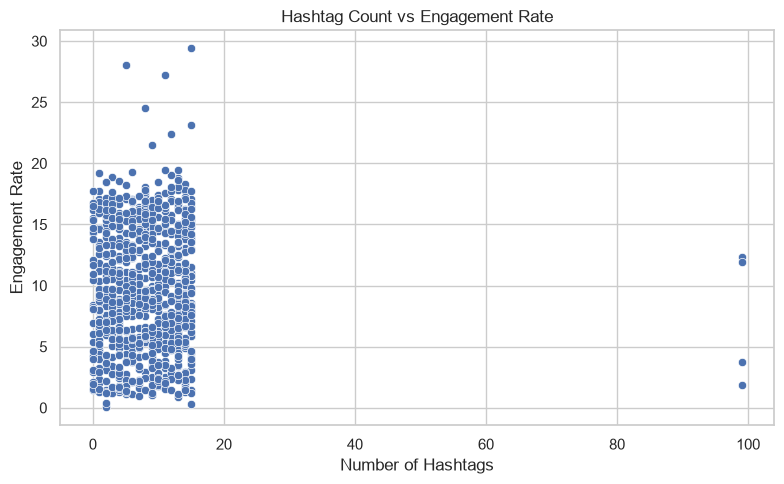

In [144]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="hashtags_count", y="engagement_rate")

plt.title("Hashtag Count vs Engagement Rate")
plt.xlabel("Number of Hashtags")
plt.ylabel("Engagement Rate")

plt.tight_layout()
plt.show()

### Observations:
- Most posts use a relatively small number of hashtags.
- Engagement rates vary significantly even for similar hashtag counts.
- No clear relationship is observed between hashtag count and engagement rate.
- Excessive hashtag usage does not necessarily result in higher engagement.

### Inference: 
Hashtag quantity alone is not a reliable indicator of post engagement.

### 6.2 Histplot

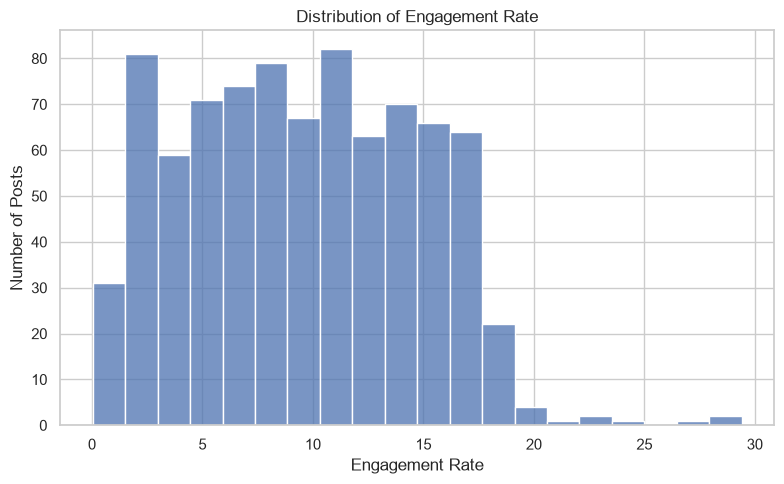

In [145]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="engagement_rate", bins=20)

plt.title("Distribution of Engagement Rate")
plt.xlabel("Engagement Rate")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

### Observations:

- Most posts have engagement rates concentrated in the lower-to-middle range.
- The frequency of posts decreases as engagement rates increase.
- Only a small number of posts achieve exceptionally high engagement.

### Inference: 
Most posts receive moderate engagement, while high engagement is relatively less frequent.

### 6.3 Heatmap

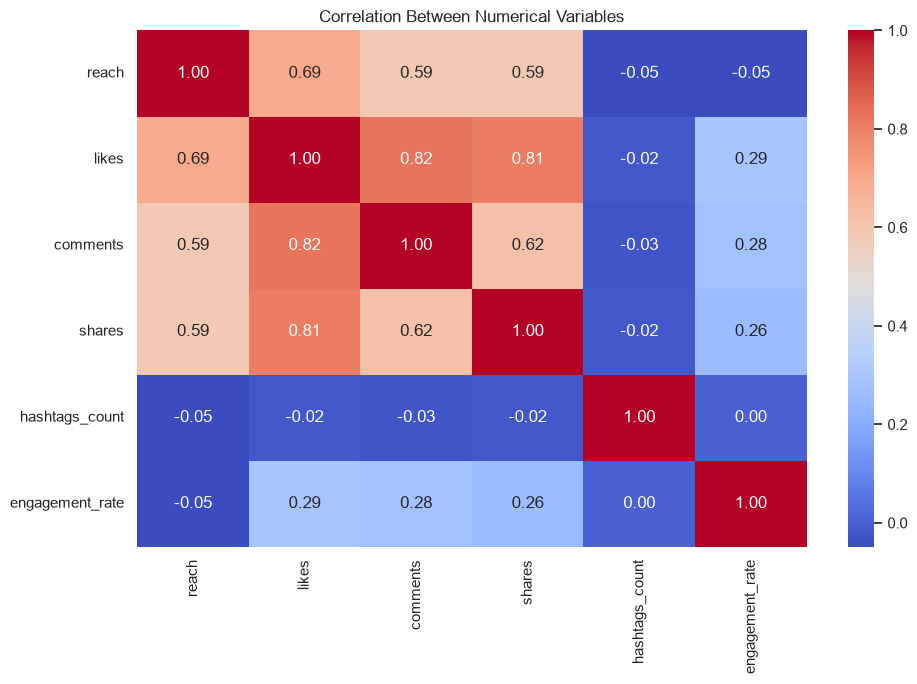

In [146]:
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

### Observations:
- Likes and comments show a strong positive correlation (0.82).
- Likes and shares also show a strong positive correlation (0.81).
- Reach has positive relationships with likes, comments, and shares.
- Hashtag count has almost zero correlation with engagement rate.
- Reach and engagement rate have a very weak negative correlation.

### Inference: 
Audience interactions are positively associated with reach, but higher reach does not necessarily indicate a higher engagement rate.

### 6.4 Line plot

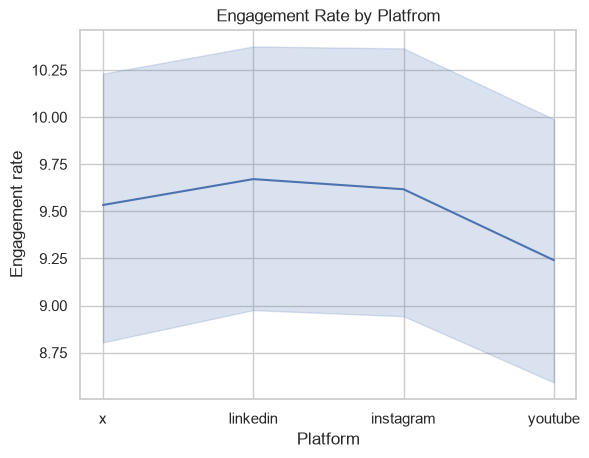

In [147]:
sns.lineplot(x = "platform", y = "engagement_rate", data = df)
plt.title("Engagement Rate by Platfrom")
plt.xlabel("Platform")
plt.ylabel("Engagement rate")
plt.show()

### Observations:
- LinkedIn has the highest average engagement rate (approximately 9.67).
- Instagram follows closely (approximately 9.62).
- X records approximately 9.53.
- YouTube records approximately 9.24.
- Differences between the platforms are relatively small.

### Inference: 
LinkedIn and Instagram show slightly higher average engagement in this dataset, but the difference is not sufficient to establish a definitive winner.

In [148]:
varia = df[["platform", "content_type"]]
print(varia)

      platform content_type
0            x         text
1            x         reel
2     linkedin        image
3            x         reel
4    instagram         text
..         ...          ...
860          x         reel
861    youtube        image
862   linkedin        video
863   linkedin        video
864   linkedin         text

[840 rows x 2 columns]


## 7. Converting cleaned dataset

- CSV export - Exported the cleaned dataset into a separate CSV file for further use.

In [149]:
# .to_csv("xx.csv") -> converts into csv file
df.to_csv('cleaned_dataset.csv', index=False)

In [150]:
print(df)

    post_id   platform           posted_at content_type  reach  likes  \
0    SM0572          x 2026-03-13 11:38:00         text   3182    112   
1    SM0339          x 2026-01-31 18:26:00         reel   1005    115   
2    SM0488   linkedin 2026-03-12 21:21:00        image   1662    156   
3    SM0400          x 2026-02-20 14:46:00         reel   1221    103   
4    SM0026  instagram 2026-02-16 08:48:00         text  19969    998   
..      ...        ...                 ...          ...    ...    ...   
860  SM0824          x 2026-02-09 19:25:00         reel    257    205   
861  SM0542    youtube 2026-03-25 09:07:00        image   2019    112   
862  SM0296   linkedin 2026-03-12 20:19:00        video  25815    429   
863  SM0667   linkedin 2026-01-31 22:25:00        video   2760    143   
864  SM0462   linkedin 2026-03-23 09:32:00         text  19473   2367   

     comments  shares  hashtags_count  engagement_rate  
0           9      38             8.0             4.24  
1        

In [151]:
df.shape

(840, 10)

### Key Insights
1. LinkedIn recorded the highest average engagement rate, followed closely by Instagram.
2. Hashtag count showed almost no linear relationship with engagement rate.
3. Likes, comments, and shares showed positive relationships with reach.
4. Higher reach does not necessarily guarantee higher engagement.
5. Different content formats may perform differently across social media platforms.
6. Most posts achieved moderate engagement, with relatively few posts recording exceptionally high engagement.

## Recommendations
1. Platform Selection: Consider LinkedIn and Instagram for engagement-focused campaigns based on their slightly higher average engagement rates.
2. Content Strategy: Identify the best-performing content formats for each platform and prioritize them according to campaign objectives.
3. Hashtag Optimization: Focus on relevant hashtags rather than increasing hashtag quantity unnecessarily.
4. Audience Engagement: Encourage likes, comments, and shares through interactive and relevant content.
5. Performance Monitoring: Evaluate both reach and engagement rate instead of relying on a single metric.

## Conclusion
- The analysis demonstrates how data cleaning and exploratory data analysis can help identify meaningful patterns in social media performance.

- The findings highlight the importance of platform selection, content strategy, and audience interaction in understanding engagement.

- Data-driven decisions can help improve social media content strategies and make better use of different platforms.

## Future Scope
Further analysis can explore posting-time patterns, monthly engagement trends, and platform-specific content performance.

## 8. Bonus Challenge - Team Name Generation Using zip()

An additional Python problem-solving challenge was completed as part of the hackathon.

Objective: Combine two input strings character by character while handling strings of different lengths.

The solution uses string operations and iteration to generate the required output.

In [152]:
left = 'P5Sihrn ytxr'
right = '5 lteigSnaes'

In [153]:
n = max(len(left), len(right))
result = ''.join(a + b for a, b in zip(left.ljust(n), right.ljust(n)))
print(result)

P55 Slithering Syntaxers
